# Lab 3: Parameter estimation and Unbiasedness of Estimators

## General comments

- At the beginning of the notebook, provide a work breakdown structure estimating the efforts of each team member.
- Submit **both** the Jupyter notebook source (`.ipynb`) **and** its **HTML** export. Name the files `team_x_lab3.ipynb` and `team_x_lab3.html`, replacing `x` with your team number (e.g. `team_07_lab3.ipynb`). Links to GitHub repositories are **NOT** accepted.
- Before you export, restart the kernel, clear all outputs and run all cells. Ensure that all cells ran correctly and there are no errors.
- All formulas **MUST** be written with LaTeX (\$...\$, \$\$...\$\$). Ensure that they are rendered correctly in your `.ipynb` and `.html` submitted files.
- The **team id number** (`ID`) used in the tasks is the ordinal number of your team in the random selection (you can find it in the assignment on the LMS). You **must** fix the random seed at the beginning of your code so that your calculations are reproducible. Draw all random numbers with `np.random` functions (e.g. `np.random.exponential`), after this seed is set.
- Not complying with these instructions may result in a **point deduction**, regardless of whether your implementation is correct.
- At the defence every team member **MUST** understand all tasks and know all derivations, formulas and results in the notebook. Not knowing any of it will result in a **point deduction**.

## Work breakdown

**Team:** 11

| Team member | Tasks |
|---|---|
| _Name Surname_ | _..._ |
| _Veronika Parkhomenko_ | _Problem 2 (Poisson): methods 2–4, simulation, comparison, conclusions; Setup (ID, seed)_ |
| _Name Surname_ | _..._ |

## Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy import stats
# All your other imports go here

ID = 11  # TODO: put your team id number here

# Fix the seed once, at the beginning of the notebook, to make all results reproducible.
# Draw all random numbers with np.random functions (e.g. np.random.exponential(scale=theta, size=(n, m)))
np.random.seed(ID)

---

## Part I: Parameter estimation

**Aim:** In Problems 1 and 2 you have to verify that the interval estimates produced by the known rules really contain the parameter with probability equal to the confidence level.

### Problem 1

The expected value of the exponential distribution $\mathscr{E}(\lambda)$ is $1/\lambda$, so the sample mean $\overline{\mathbf{X}}$ is a good point estimate of the parameter $\theta := 1/\lambda$. A confidence interval for $\theta$ can be formed in several different ways:

1. Using the exact distribution of the statistic $2\lambda n\overline{\mathbf{X}}$ (show that it is $\chi^2_{2n}$, then use the quantiles of the latter to get the interval endpoints).

2. Using the normal approximation $\mathscr{N}(\mu, \sigma^2)$ for $\overline{\mathbf{X}}$, with parameters $\mu = \theta$ and $\sigma^2 = s^2/n$, where $s^2 = \theta^2$ is the population variance (the variance of the original distribution $\mathscr{E}(\lambda)$). In other words, form the $Z$-statistic $Z := \sqrt{n}\,(\overline{\mathbf{X}} - \theta)/\theta$ and use the fact that it is approximately standard normal $\mathscr{N}(0, 1)$:

   $$\mathsf{P}\big(|\theta - \overline{\mathbf{X}}| \le z_\beta\, \theta/\sqrt{n}\big) = \mathsf{P}(|Z| \le z_\beta) = 2\beta - 1,$$

   so $\theta$ lies within $\overline{\mathbf{X}} \pm z_\beta\,\theta/\sqrt{n}$ with probability $2\beta - 1$. (Here $z_\beta$ is the $\beta$-quantile of $\mathscr{N}(0, 1)$).

3. The confidence interval constructed above uses the unknown variance $s^2 = \theta^2$, so it is of little use in practice. Instead, solve the double inequality

   $$|\theta - \overline{\mathbf{X}}| \le z_\beta\, \theta/\sqrt{n}$$

   for $\theta$. This gives another confidence interval that does not depend on the unknown parameter.

4. Another, more universal way to remove the dependence on $\theta$ in (2) is to estimate $s$ by the sample standard deviation and approximate $\overline{\mathbf{X}}$ with the Student $t$-distribution (see Ross's textbook on statistics or the lecture notes for details).

**Task:**

   **(a)** Derive confidence intervals for each of the 4 methods above.

   **(b)** For each method, estimate the actual confidence (the fraction of intervals containing $\theta = 1/\lambda$, which should be close to $1-\alpha$) and the interval lengths. Use $\theta = \texttt{ID}/10$, $\alpha = 0.1;\ 0.05;\ 0.01$, and vary the sample size $n$ and the number of repetitions $m$. Choose convenient visualizations (tables, plots against $n$, etc.) to compare all methods at a glance.

   **(c)** Explain how $n$ and $m$ affect the probability that the parameter lies in each of the four random intervals above, and the lengths of these intervals.

   **(d)** Compare all 4 methods: what are the pros and cons of each, which is the best, and in which cases.


#### Solution

_Your derivations and discussion here._

In [2]:
# Your code here

#### Conclusion

_Your conclusion here._

---

### Problem 2

Repeat parts (2)–(4) of Problem 1 (with the corresponding amendments) for a Poisson distribution $\mathscr{P}(\theta)$.

The **Task** stays the same: derive the intervals, check that they contain the parameter $\theta$ with the prescribed probability, find their lengths, compare the methods and write your conclusions.

#### Solution

Let $X_1,\dots,X_n \sim \mathscr{P}(\theta)$ i.i.d. Then $\mathsf{E}X=\theta$ and $\mathrm{Var}\,X=\theta$, so $s^2=\theta$. Let $\beta = 1-\alpha/2$ and $z_\beta$ be the $\beta$-quantile of $\mathscr{N}(0,1)$.

**Method 2 (normal approximation, known variance).** By the CLT, $\overline{\mathbf X}\approx\mathscr N(\theta,\theta/n)$, so
$$Z=\frac{\sqrt n\,(\overline{\mathbf X}-\theta)}{\sqrt\theta}\approx \mathscr N(0,1),\qquad \mathsf P\big(|\theta-\overline{\mathbf X}|\le z_\beta\sqrt{\theta/n}\big)\approx 2\beta-1 = 1-\alpha.$$
Interval: $\;\overline{\mathbf X}\pm z_\beta\sqrt{\theta/n}$. It uses the unknown $\theta$, so it is not usable in practice; we still simulate it (with the true $\theta$) as a benchmark. Its length $2z_\beta\sqrt{\theta/n}$ is deterministic.

**Method 3 (solving the inequality for $\theta$).** Squaring $|\theta-\overline{\mathbf X}|\le z_\beta\sqrt{\theta/n}$ gives
$$\theta^2-\Big(2\overline{\mathbf X}+\frac{z_\beta^2}{n}\Big)\theta+\overline{\mathbf X}^2\le 0 .$$
The roots of the quadratic are
$$\theta_{1,2}=\overline{\mathbf X}+\frac{z_\beta^2}{2n}\pm z_\beta\sqrt{\frac{\overline{\mathbf X}}{n}+\frac{z_\beta^2}{4n^2}},$$
and the interval is $[\theta_1,\theta_2]$. It does not depend on the unknown parameter. Its length is $2z_\beta\sqrt{\overline{\mathbf X}/n+z_\beta^2/(4n^2)}$ (random).

**Method 4 (Student $t$).** Estimate $s$ by $S=\sqrt{\frac1{n-1}\sum(X_i-\overline{\mathbf X})^2}$ and use $T=\sqrt n(\overline{\mathbf X}-\theta)/S\approx t_{n-1}$:
$$\overline{\mathbf X}\pm t_{n-1,\beta}\frac{S}{\sqrt n}.$$
Note: if all $X_i=0$ then $\overline{\mathbf X}=S=0$ and the interval degenerates to a point.

**Simulation plan.** For every $n$ and $\alpha\in\{0.1,0.05,0.01\}$ we generate $m$ samples with `np.random.poisson`, build the three intervals for each sample, and compute (i) the empirical confidence = fraction of intervals containing $\theta$ and (ii) the mean interval length. The standard error of an empirical confidence $\hat p$ is $\sqrt{\hat p(1-\hat p)/m}$, so $m$ controls only the precision of the estimate, while $n$ controls the quality of the approximation. We use $\theta=\texttt{ID}/10=1.1$ and also larger $\theta$ to see the effect of the Poisson mean.


=== alpha = 0.1  (nominal confidence 0.9) ===
method  2: normal (true var)  3: solve inequality  4: Student t
n                                                              
5                     0.9178               0.9178        0.8937
10                    0.9092               0.9092        0.8781
20                    0.8886               0.8886        0.8895
50                    0.9094               0.9094        0.8977
100                   0.9024               0.9024        0.8920
200                   0.9043               0.9043        0.9005
500                   0.8986               0.8986        0.8993
1000                  0.8978               0.8978        0.8974
--- mean length ---
method  2: normal (true var)  3: solve inequality  4: Student t
n                                                              
5                     1.5430               1.6001        1.8507
10                    1.0911               1.1109        1.1687
20                    0.7715         

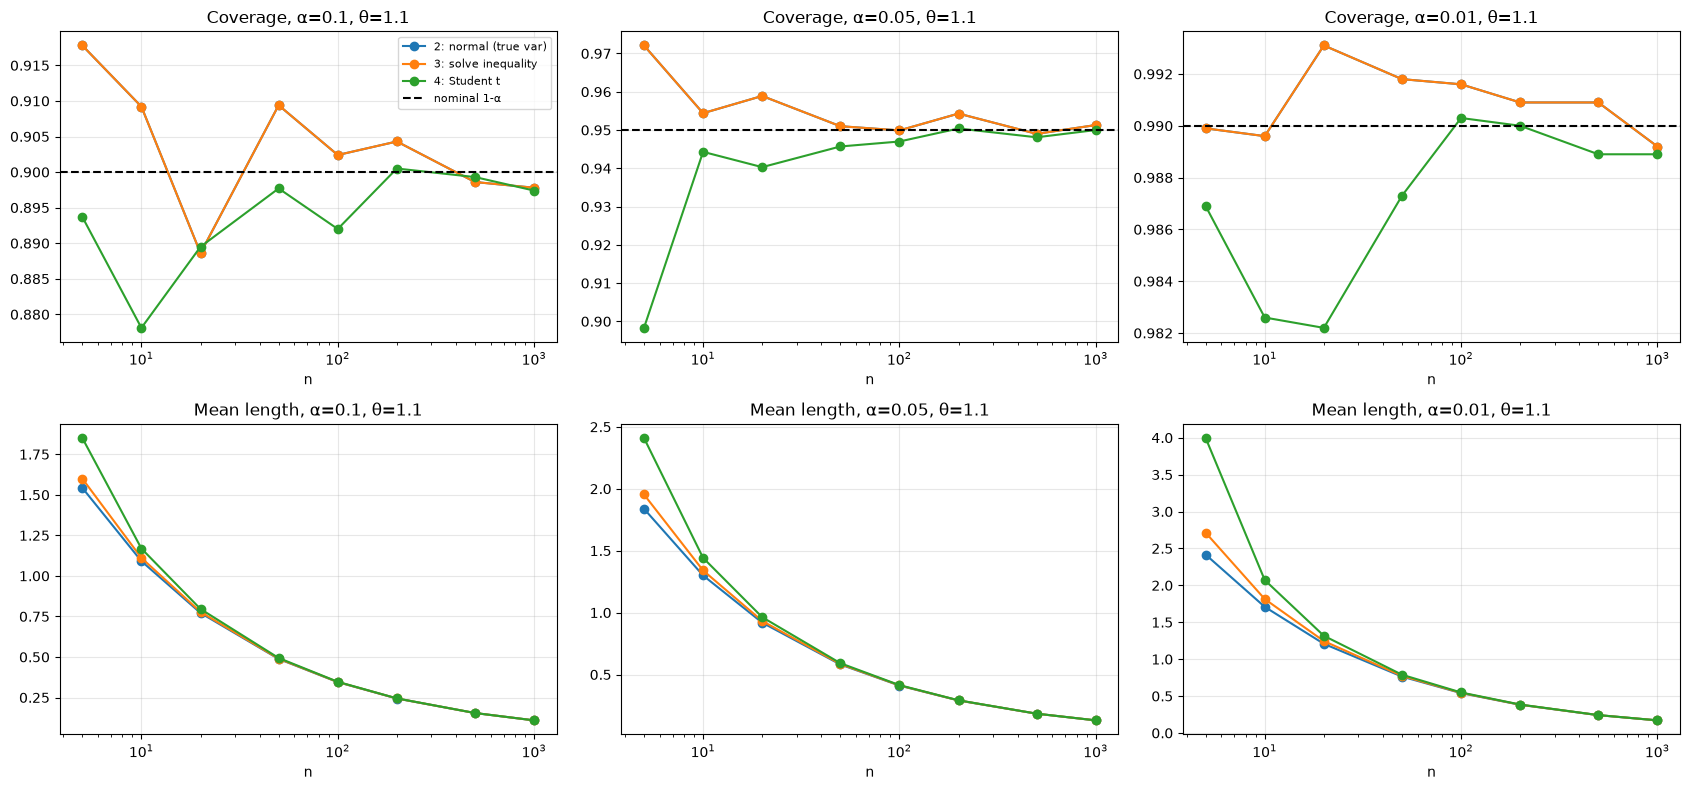


=== Effect of m (n=50, alpha=0.05) ===
method  2: normal (true var)  3: solve inequality  4: Student t
m                                                              
100                   0.9500               0.9500        0.9200
1000                  0.9520               0.9520        0.9470
10000                 0.9545               0.9545        0.9463
100000                0.9496               0.9496        0.9449


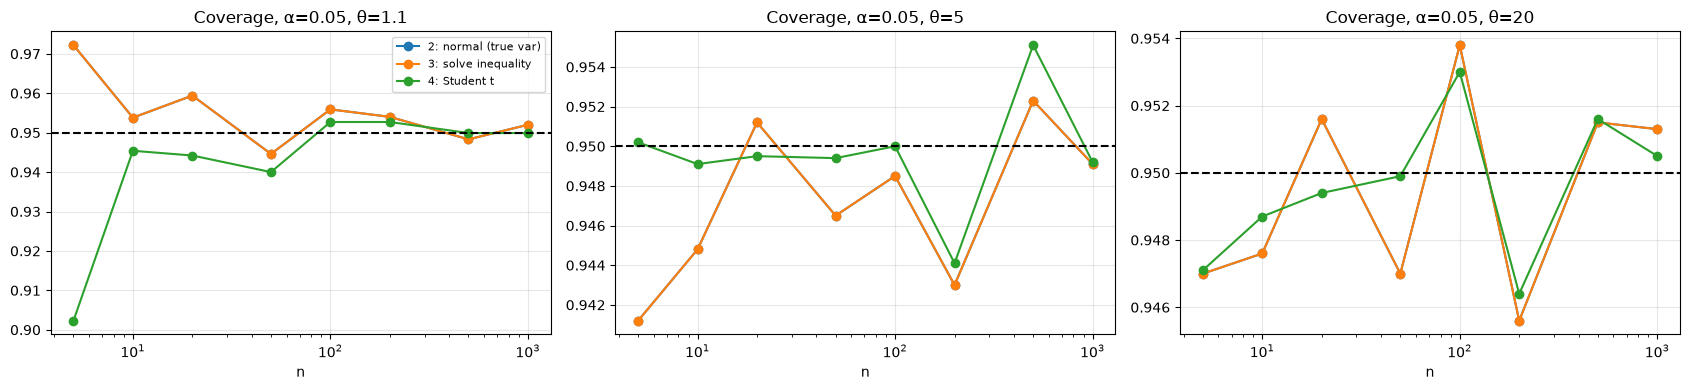

In [3]:
THETA = ID / 10                      # 1.1
ALPHAS = [0.1, 0.05, 0.01]
NS = [5, 10, 20, 50, 100, 200, 500, 1000]
M = 10000
METHODS = ["2: normal (true var)", "3: solve inequality", "4: Student t"]

def poisson_intervals(x, theta, alpha):
    """x: array (m, n) of Poisson samples. Returns {method: (lo, hi)} with arrays of length m."""
    m, n = x.shape
    beta = 1 - alpha / 2
    z = stats.norm.ppf(beta)
    t = stats.t.ppf(beta, df=n - 1)
    xbar = x.mean(axis=1)
    s = x.std(axis=1, ddof=1)

    # Method 2: uses the true theta in the variance
    h2 = z * np.sqrt(theta / n)
    # Method 3: roots of the quadratic inequality
    centre3 = xbar + z**2 / (2 * n)
    h3 = z * np.sqrt(xbar / n + z**2 / (4 * n**2))
    # Method 4: Student t with sample std
    h4 = t * s / np.sqrt(n)

    return {
        METHODS[0]: (xbar - h2, xbar + h2),
        METHODS[1]: (centre3 - h3, centre3 + h3),
        METHODS[2]: (xbar - h4, xbar + h4),
    }

def simulate(theta, ns, alphas, m):
    rows = []
    for n in ns:
        x = np.random.poisson(lam=theta, size=(m, n))
        for a in alphas:
            for meth, (lo, hi) in poisson_intervals(x, theta, a).items():
                rows.append({
                    "theta": theta, "n": n, "m": m, "alpha": a, "method": meth,
                    "coverage": np.mean((lo <= theta) & (theta <= hi)),
                    "length": np.mean(hi - lo),
                })
    return pd.DataFrame(rows)

# Main experiment: theta = ID/10
df_main = simulate(THETA, NS, ALPHAS, M)

for a in ALPHAS:
    print(f"\n=== alpha = {a}  (nominal confidence {1-a}) ===")
    print(df_main[df_main.alpha == a]
          .pivot(index="n", columns="method", values="coverage").round(4))
    print("--- mean length ---")
    print(df_main[df_main.alpha == a]
          .pivot(index="n", columns="method", values="length").round(4))

# Plots: coverage and length vs n
fig, axes = plt.subplots(2, 3, figsize=(17, 8))
for j, a in enumerate(ALPHAS):
    sub = df_main[df_main.alpha == a]
    for meth in METHODS:
        d = sub[sub.method == meth]
        axes[0, j].plot(d.n, d.coverage, marker="o", label=meth)
        axes[1, j].plot(d.n, d.length, marker="o", label=meth)
    axes[0, j].axhline(1 - a, color="k", ls="--", label="nominal 1-α")
    axes[0, j].set_title(f"Coverage, α={a}, θ={THETA}")
    axes[1, j].set_title(f"Mean length, α={a}, θ={THETA}")
    for i in range(2):
        axes[i, j].set_xscale("log"); axes[i, j].set_xlabel("n"); axes[i, j].grid(alpha=.3)
axes[0, 0].legend(fontsize=8)
plt.tight_layout(); plt.show()

# Effect of m (fixed n = 50, alpha = 0.05)
rows = []
for m in [100, 1000, 10000, 100000]:
    d = simulate(THETA, [50], [0.05], m)
    rows.append(d)
df_m = pd.concat(rows)
print("\n=== Effect of m (n=50, alpha=0.05) ===")
print(df_m.pivot(index="m", columns="method", values="coverage").round(4))

# Effect of theta (alpha = 0.05)
df_theta = pd.concat([simulate(th, NS, [0.05], M) for th in [THETA, 5, 20]])
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, th in zip(axes, [THETA, 5, 20]):
    sub = df_theta[df_theta.theta == th]
    for meth in METHODS:
        d = sub[sub.method == meth]
        ax.plot(d.n, d.coverage, marker="o", label=meth)
    ax.axhline(0.95, color="k", ls="--")
    ax.set_xscale("log"); ax.set_title(f"Coverage, α=0.05, θ={th}")
    ax.set_xlabel("n"); ax.grid(alpha=.3)
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

#### Conclusion

- **Effect of $n$.** As $n$ grows, the empirical confidence of all three methods approaches the nominal $1-\alpha$ and the interval length shrinks like $1/\sqrt n$. For small $n$ and $\theta=1.1$ the coverage is not smooth: the Poisson law is discrete and skewed, so methods 2 and 3 over-cover, while method 4 under-covers noticeably.
- **Effect of $m$.** $m$ does not change the true coverage probability, it only reduces the noise of its estimate (standard error $\sqrt{\hat p(1-\hat p)/m}\approx 0.002$ for $m=10^4$). For $m=100$ the estimates are very noisy, for $m\ge10^4$ they are stable.
- **Effect of $\alpha$.** Smaller $\alpha$ gives longer intervals (larger $z_\beta$). For small $n$ the deviation of the coverage from $1-\alpha$ is not monotone in $\alpha$ (for $n=5$, $\theta=1.1$ it is about $0.018$ for $\alpha=0.1$, $0.022$ for $\alpha=0.05$ and close to $0$ for $\alpha=0.01$), because the coverage of a discrete distribution depends on where the interval endpoints fall relative to the integer-valued sample sums.
- **Effect of $\theta$.** For $\theta=5$ and $\theta=20$ the coverage of all methods stays within about $0.01$ of $0.95$ already for small $n$. The remaining zigzag comes from the discreteness of the Poisson distribution (the sample sum is integer-valued, so coverage jumps with $n$) and from Monte Carlo noise. For small $\theta n$ many samples consist of zeros only.
- **Methods 2 and 3 have identical coverage.** Squaring $|\theta-\overline{\mathbf X}|\le z_\beta\sqrt{\theta/n}$ is an equivalent transformation, so on the same samples the events "$\theta\in$ interval 2" and "$\theta\in$ interval 3" coincide. They differ only in length: $L_2<L_3<L_4$ for small $n$, and all three merge for large $n$.
- **Comparison.** Method 2 needs the unknown $\theta$ and is only a benchmark. Method 3 uses only $\overline{\mathbf X}$ and never degenerates (for $\overline{\mathbf X}=0$ it gives $[0,z_\beta^2/n]$), but relies on the Poisson variance formula $s^2=\theta$. Method 4 is universal (no distribution-specific variance is needed), but for small $\theta n$ the estimate $S$ is unreliable and the interval collapses to a point when all $X_i=0$, which gives the worst coverage.
- **Best method:** method 3 for small $n$ / small $\theta$ when the data are known to be Poisson; method 4 when the variance model is unknown and $n$ is large; for large $n$ all methods are practically equivalent.

---

## Part II: Unbiasedness of Estimators

### Problem 3

In this task you need to analyze the estimators of the variance and their properties: we will prove the unbiasedness of the variance estimator theoretically and check it in practice!

There are two common estimators of the population variance:
$$
\sigma^2_n = \frac{1}{n}\sum_{i=1}^{n}(X_i - \overline{X})^2,
\qquad
\sigma^2_{n-1} = \frac{1}{n-1}\sum_{i=1}^{n}(X_i - \overline{X})^2.
$$

**Task:**

**(a)** Write code to generate a dataset of i.i.d. samples from $\mathcal{N}(\mu, \sigma^2)$ with $\mu = \texttt{ID}$ and $\sigma^2 = (\texttt{ID} \bmod 5) + 2$, and find the variance of the dataset.

**(b)** Find $\sigma^2_n$ and $\sigma^2_{n-1}$ for $n = 10$, $n = 50$, $n = 100$, $n = 1000$.

**(c)** Find the biases $Bias(\sigma^2_n) = E(\sigma^2_n) - \sigma^2$ and $Bias(\sigma^2_{n-1}) = E(\sigma^2_{n-1}) - \sigma^2$ (estimate the expectations by averaging over many simulated datasets).

**(d)** Comment on the results for the different values of $n$.

**(e)** Derive analytically the expected value of each estimator, $E(\sigma^2_n)$ and $E(\sigma^2_{n-1})$.

**(f)** Using the expected values found above, show mathematically which of the two estimators is unbiased.

**(g)** Comment on the results of the theoretical and practical tasks.

#### Solution

_Your derivations and discussion here._

In [4]:
# Your code here

#### Conclusion

_Your conclusion here._